# Step 6 — Is it already known? Cross-matching candidates against catalogs

This notebook is a *walkthrough* of what `src/known.py` does. As in the previous notebooks,
every piece is built by hand and explained, then applied to a few real signals from our
sector.

Where we are in the pipeline (see `docs/PLAN_milestone1.md`, §8):

| step | module | reads | writes |
|---|---|---|---|
| 4 | `src/search.py` | flattened light curves | `data/search/sector_104.parquet` |
| 5 | `src/vet.py` | step 4 + light curves | `data/search/sector_104_vetted.parquet` (49 signals pass all hard tests) |
| **6** | **`src/known.py`** | **step 5 table + public catalogs** | **`data/search/sector_104_known.parquet`: every signal tagged known / blend / new** |
| 7 | `src/report.py` | step 6 | one page per candidate, known ones at the bottom |

### The question

Vetting tells us a signal *looks like* a planet. The milestone asks for **new** candidates,
so before anyone spends time on a signal we must answer three questions:

1. **Is this exact signal already catalogued?** It could be a confirmed planet, a TESS Object
   of Interest (TOI), a community TOI, or a known eclipsing binary. If so, it is a
   *successful recovery*, which is good for calibration but not a discovery.
2. **Does a *neighbouring* star host a known object with the same period?** Then our
   signal is most likely light from that object leaking into our aperture (a **blend**). It
   could also be the reverse: our star is the true source and the catalog entry is attached
   to the wrong star.
3. **Does another star *in our own sector* show the same signal?** Same physics, but the
   neighbour's object is not catalogued anywhere.

Only a signal that answers "no" to all three is a **new candidate**.

The matching key is never the star's name. It is the **TIC ID** when we ask "same star?",
and the **sky position plus the ephemeris (period and epoch)** when we ask "same signal?".

Sections:

1. Inputs: the vetted table
2. The catalogs: what each one is, what its columns and disposition codes mean
3. One schema for all catalogs
4. Match 1: same star (TIC ID). Is it the same *signal*? Period aliases and tolerance
5. Match 2: the ephemeris, i.e. propagating a catalogued transit time to our sector
6. Match 3: neighbours. Angular separation, TESS pixels, and the dilution argument
7. Match 4: siblings inside our own sector
8. Gaia DR3 eclipsing binaries around the candidates
9. Putting it together: `classify()` on the 49 survivors
10. Checklist for writing `known.py`

## 1. Inputs

`vet.py` wrote one row per star. We also need each star's sky position and TESS magnitude
from the target table (step 1).

In [1]:
import io
import os
import warnings
from datetime import date
from pathlib import Path

import dotenv
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.vizier import Vizier

warnings.filterwarnings("ignore", module="astroquery")
ROOT = Path("..")
dotenv.load_dotenv(ROOT / ".env")
SECTOR = int(os.environ["SECTOR"])
DATA_DIR = ROOT / "data"
KNOWN_DIR = DATA_DIR / "known" / date.today().isoformat()  # dated copies: catalogs change weekly
KNOWN_DIR.mkdir(parents=True, exist_ok=True)
BTJD0 = 2457000.0  # BTJD = BJD - 2457000

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

vetted = pd.read_parquet(DATA_DIR / "search" / f"sector_{SECTOR}_vetted.parquet")
targets = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}.parquet",
                          columns=["tic_id", "ra", "dec", "tmag", "gaia_dr2_id"])
sig = vetted.merge(targets, on="tic_id", how="left").set_index("tic_id")
cand = sig[sig["passes_all"]]
print(f"{len(sig)} signals, {len(cand)} pass all hard tests")
cand[["period", "T0", "depth_ppm", "duration_h", "rp_earth", "snr", "flags"]].head(12)

4693 signals, 49 pass all hard tests


,period,T0,depth_ppm,duration_h,rp_earth,snr,flags
tic_id,,,,,,,
410153553,0.462953,4180.149421,4748.151035,0.456135,1.275004,30.517129,
234994474,1.401555,4180.940730,631.998921,1.188828,1.472278,17.614948,
370133522,0.518241,4180.016781,721.001767,0.671740,1.029876,16.695899,
262530407,2.854504,4180.715687,1427.987152,1.119274,1.919397,15.099572,
49143293,9.048854,4185.112632,42591.896425,1.880286,5.992533,12.324321,
351601843,0.604772,4180.234410,826.567679,0.868004,1.636710,11.861009,
161032923,3.964947,4179.925472,4155.156736,0.823326,1.264591,8.857441,
394585043,4.495943,4179.830483,7335.493520,0.814879,2.422301,7.653677,
118327550,7.395137,4183.114388,1110.050196,1.187067,1.330540,7.539422,


`T0` is the mid-time of our first transit in **BTJD** (BJD − 2,457,000 days; BJD is the
Barycentric Julian Date, i.e. time measured at the centre of mass of the Solar System, so that
light-travel time across Earth's orbit is removed). Every catalog below gives epochs in full
BJD, so we subtract 2,457,000 to compare.

## 2. The catalogs

| catalog | what it is | how we get it | size |
|---|---|---|---|
| **TOI** (TESS Objects of Interest) | Signals the TESS team itself flagged for follow-up, from the SPOC and QLP pipelines. Each has a number like 136.01 (star 136, signal 01). | CSV from ExoFOP | ~8,000 |
| **CTOI** (Community TOIs) | Signals submitted by outside researchers (citizen science, independent searches). Some are later promoted to TOIs. | CSV from ExoFOP | ~5,000 |
| **Confirmed planets** | Every published planet, with the adopted best parameters (`pscomppars` table). | TAP query to the NASA Exoplanet Archive | ~6,000 |
| **TESS EBs** (Prša et al. 2022) | Eclipsing binaries found in TESS 2-min data of **sectors 1–26** only. | VizieR `J/ApJS/258/16` | 4,584 |
| **Gaia DR3 EBs** (Mowlavi et al. 2023) | ~2 million eclipsing binaries found in Gaia photometry, all-sky. Too large to download; we query cones around our candidates. | VizieR `I/358/veb` | 2.2 M |

**Disposition codes** (what the TESS Follow-up Observing Program working group, TFOPWG, has
concluded about a TOI):

| code | meaning |
|---|---|
| PC | planet candidate, nothing ruled out yet |
| APC | *ambiguous* planet candidate: some evidence against it (e.g. V-shaped, possible nearby EB) |
| CP | confirmed planet (mass measured or statistically validated) |
| KP | known planet: it was already known before TESS (e.g. from a ground-based survey) |
| FP | false positive (an EB, a blend, a variable…) |
| FA | false alarm: no astrophysical signal, a systematic |

A TOI with FP/FA is still a "known" object for us. Someone has already looked at it and
rejected it, and that is useful information.

### Downloading

Each download is one HTTP request. We save the raw files in `data/known/<today>/` so a re-run
on the same day does not hit the servers again, and so we can always tell *which version* of a
catalog a result came from.

In [2]:
URLS = {
    "toi.csv": "https://exofop.ipac.caltech.edu/tess/download_toi.php?sort=toi&output=csv",
    "ctoi.csv": "https://exofop.ipac.caltech.edu/tess/download_ctoi.php?sort=ctoi&output=csv",
    "pscomppars.csv": (
        "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?format=csv&query="
        "select+pl_name,hostname,tic_id,ra,dec,sy_tmag,pl_orbper,pl_orbpererr1,pl_tranmid,pl_tranmiderr1,"
        "pl_trandep,pl_rade,tran_flag+from+pscomppars"
    ),
}


def fetch(name: str) -> Path:
    '''Download one catalog into today's folder (once per day).'''
    path = KNOWN_DIR / name
    if not path.exists():
        r = requests.get(URLS[name], timeout=300)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path


def fetch_tess_ebs() -> Path:
    path = KNOWN_DIR / "tess_ebs.parquet"
    if not path.exists():
        t = Vizier(columns=["TIC", "m_TIC", "RAJ2000", "DEJ2000", "Tmag", "BJD0", "e_BJD0", "Per", "e_Per", "Morph"],
                   row_limit=-1).get_catalogs("J/ApJS/258/16/tess-ebs")[0]
        t.to_pandas().to_parquet(path, index=False)
    return path


raw = {
    "toi": pd.read_csv(fetch("toi.csv")),
    "ctoi": pd.read_csv(fetch("ctoi.csv")),
    "planet": pd.read_csv(fetch("pscomppars.csv")),
    "tess_eb": pd.read_parquet(fetch_tess_ebs()),
}
{k: v.shape for k, v in raw.items()}

{'toi': (8148, 63),
 'ctoi': (5137, 74),
 'planet': (6375, 13),
 'tess_eb': (4584, 10)}

## 3. One schema for all catalogs

Each catalog names the same quantity differently (`Period (days)`, `pl_orbper`, `Per`),
uses a different epoch convention (full BJD vs BTJD), and even writes coordinates differently
(the TOI table uses sexagesimal `21:14:56.88`, the others use decimal degrees). Writing a
matcher for each would be four copies of the same logic with four sets of bugs.

So the first step is to translate every catalog into **one table with one schema**:

| column | meaning |
|---|---|
| `catalog`, `obj_id`, `name` | where it comes from, its identifier in that catalog, a readable name |
| `tic_id` | the star (NaN for Gaia, which uses its own source IDs) |
| `ra`, `dec` | degrees, ICRS |
| `tmag` | TESS magnitude of the host (needed for the dilution argument, §6) |
| `period`, `period_err` | days |
| `epoch`, `epoch_err` | a mid-transit / primary-eclipse time, **BTJD** |
| `depth_ppm` | as catalogued (meaning varies a little between catalogs) |
| `disposition` | TFOPWG / user disposition, or `EB` / `CP` |

Sanity cleaning happens here too. **CTOIs are typed in by people**, and a few have epochs
like 2.40×10⁶ or 2.46×10⁷ BJD (typos). Any epoch outside the TESS era (BJD 2,458,000 to
2,470,000) becomes NaN, which means "phase unknown" (§5), not a crash. Missing periods
also stay NaN: a row with no period can still match by TIC ID (same star), just not by
ephemeris.

In [3]:
KNOWN_COLS = ["catalog", "obj_id", "name", "tic_id", "ra", "dec", "tmag", "period", "period_err",
              "epoch", "epoch_err", "depth_ppm", "disposition"]


def _btjd(bjd):
    '''Full BJD -> BTJD; anything outside the TESS era (typos in community tables) -> NaN.'''
    bjd = pd.to_numeric(bjd, errors="coerce")
    return (bjd - BTJD0).where((bjd > 2458000) & (bjd < 2470000))


def norm_toi(t):
    c = SkyCoord(t["RA"].values, t["Dec"].values, unit=(u.hourangle, u.deg))  # sexagesimal strings
    return pd.DataFrame({
        "catalog": "toi", "obj_id": t["TOI"].map(lambda x: f"TOI-{x:.2f}"),
        "name": t["Planet Name"].fillna(""), "tic_id": t["TIC ID"], "ra": c.ra.deg, "dec": c.dec.deg,
        "tmag": t["TESS Mag"], "period": t["Period (days)"], "period_err": t["Period (days) err"],
        "epoch": _btjd(t["Epoch (BJD)"]), "epoch_err": t["Epoch (BJD) err"], "depth_ppm": t["Depth (ppm)"],
        "disposition": t["TFOPWG Disposition"].fillna(t["TESS Disposition"]),
    })


def norm_ctoi(t):
    return pd.DataFrame({
        "catalog": "ctoi", "obj_id": t["CTOI"].map(lambda x: f"CTOI-{x:.2f}"),
        "name": t["Promoted to TOI"].map(lambda x: f"TOI-{x:.2f}" if pd.notna(x) else ""),
        "tic_id": t["TIC ID"], "ra": t["RA"], "dec": t["Dec"], "tmag": t["TESS Mag"],
        "period": t["Period (days)"], "period_err": t["Period (days) Error"],
        "epoch": _btjd(t["Transit Epoch (BJD)"]), "epoch_err": t["Transit Epoch (BJD) err"],
        "depth_ppm": t["Depth ppm"], "disposition": t["TFOPWG Disposition"].fillna(t["User Disposition"]),
    })


def norm_planet(t):
    t = t[t["tic_id"].notna()]
    return pd.DataFrame({
        "catalog": "planet", "obj_id": t["pl_name"], "name": t["pl_name"],
        "tic_id": t["tic_id"].str.replace("TIC ", "").astype("int64"), "ra": t["ra"], "dec": t["dec"],
        "tmag": t["sy_tmag"], "period": t["pl_orbper"], "period_err": t["pl_orbpererr1"],
        "epoch": _btjd(t["pl_tranmid"]), "epoch_err": t["pl_tranmiderr1"],
        "depth_ppm": t["pl_trandep"] * 1e4,  # the archive gives depth in %
        "disposition": "CP",
    })


def norm_tess_eb(t):
    return pd.DataFrame({
        "catalog": "tess_eb", "obj_id": t["TIC"].astype(str).str.lstrip("0") + "." + t["m_TIC"].astype(str),
        "name": "", "tic_id": t["TIC"].astype("int64"), "ra": t["RAJ2000"], "dec": t["DEJ2000"],
        "tmag": t["Tmag"], "period": t["Per"], "period_err": t["e_Per"],
        "epoch": t["BJD0"], "epoch_err": t["e_BJD0"],  # already BTJD in this catalog
        "depth_ppm": np.nan, "disposition": "EB",
    })


known = pd.concat([norm_toi(raw["toi"]), norm_ctoi(raw["ctoi"]), norm_planet(raw["planet"]),
                   norm_tess_eb(raw["tess_eb"])], ignore_index=True)
known["tic_id"] = known["tic_id"].astype("Int64")
print(known.groupby("catalog").agg(rows=("obj_id", "size"), with_period=("period", "count"),
                                   with_epoch=("epoch", "count")))
known.sample(5, random_state=1)

         rows  with_period  with_epoch
catalog                               
ctoi     5137         4268        5014
planet   6068         5996        1238
tess_eb  4584         4582        4578
toi      8148         8148        8147


,catalog,obj_id,name,tic_id,ra,dec,tmag,period,period_err,epoch,epoch_err,depth_ppm,disposition
23915,tess_eb,285392907.1,,285392907,272.886866,23.920181,9.80100,8.464757,0.001632,2012.369586,0.002071,NaN,EB
22268,tess_eb,259373684.1,,259373684,68.135765,-50.215312,10.95400,21.686787,0.000047,1403.178064,0.002749,NaN,EB
2371,toi,TOI-2271.01,,258389327,296.710292,70.071944,11.82480,26.545681,0.000017,1957.320501,0.000732,9362.30077,APC
11813,ctoi,CTOI-317001596.01,,317001596,279.970916,25.587956,9.30456,5.288961,NaN,NaN,NaN,987.44670,PC
1315,toi,TOI-1293.01,,202504234,230.310083,63.565286,10.86050,1.684994,0.000003,2689.485255,0.001219,990.00000,PC


## 4. Match 1: the same star

The easy part. A signal and a catalog entry refer to the same star when their **TIC IDs**
are equal. It is a table join.

In [4]:
same_star = known[known["tic_id"].isin(cand.index)]
print(f"{same_star['tic_id'].nunique()} of the {len(cand)} candidates have at least one catalog entry on the same star")
same_star.merge(cand[["period", "depth_ppm"]], left_on="tic_id", right_index=True, suffixes=("", "_ours"))[
    ["tic_id", "catalog", "obj_id", "name", "disposition", "period", "period_ours", "depth_ppm", "depth_ppm_ours"]]

9 of the 49 candidates have at least one catalog entry on the same star


,tic_id,catalog,obj_id,name,disposition,period,period_ours,depth_ppm,depth_ppm_ours
37,234994474,toi,TOI-134.01,,CP,1.401518,1.401555,593.754092,631.998921
39,410153553,toi,TOI-136.01,,CP,0.462930,0.462953,4507.326877,4748.151035
88,262530407,toi,TOI-177.01,,CP,2.853102,2.854504,1547.106893,1427.987152
166,118327550,toi,TOI-244.01,,CP,7.397216,7.395137,953.547750,1110.050196
1075,351601843,toi,TOI-1075.01,,CP,0.604739,0.604772,1027.683348,826.567679
1078,370133522,toi,TOI-1078.01,,CP,0.518242,0.518241,831.892042,721.001767
1080,161032923,toi,TOI-1080.01,,CP,3.965248,3.964947,3680.754444,4155.156736
4702,248250955,toi,TOI-4552.01,,CP,0.301151,0.301066,1457.697398,1919.824242
12419,381856446,ctoi,CTOI-381856446.01,,PC,1.769000,1.768329,35156.390000,32660.502352
13626,410153553,planet,LHS 3844 b,LHS 3844 b,CP,0.462930,0.462953,696.000000,4748.151035


**Same star is not the same signal.** A star can host several planets: TOI-700 has
three, and multi-planet systems are common around M dwarfs. If we found a *different* period
on a star that already has a TOI, that is a potential **new planet in a known system**, which
is the most valuable kind of result. So for every same-star entry we still compare periods.

### Period aliases

Our period can legitimately differ from the catalogued one by a small integer factor:

- **½ or ⅓**: TLS can lock onto a period at which only every other "transit" is real if the
  real transits fall in gaps. Or the catalog entry is an EB whose two similar eclipses we
  folded together (vetting §6). Then our P = P_EB / 2.
- **2 or 3**: we found only every second transit (the others were in gaps), or the catalog
  has the half-period alias.

So we test $P_{\rm ours} \approx r\,P_{\rm cat}$ for $r \in \{1/3, 1/2, 1, 2, 3\}$.

### How close is "≈"?

The relative difference $|P_{\rm ours} - r P_{\rm cat}| / P_{\rm ours}$ must be below a
tolerance. Two constraints set it:

- **Large enough to accept real matches.** Our period comes from one ~25-day sector. Its
  error is roughly (timing error of one transit) / (number of orbits in the baseline), which
  gives typical relative errors of 10⁻⁴ to 10⁻³. TLS's own `period_unc` (the half-width of the
  periodogram peak, median 0.5 %) is a much more pessimistic number.
- **Small enough to reject chance coincidences.** If periods were spread uniformly in
  log P over our search range (0.2–13 d, i.e. ln(65) ≈ 4.2 in log units), the chance that
  an *unrelated* object matches one of 5 ratios within ±tol is
  $p \approx 5 \times 2\,\text{tol} / 4.2$.

The cell below measures the actual differences for the 8 confirmed planets in our
candidate list, and computes the chance-match probability for a few tolerances.

In [5]:
RATIOS = (1 / 3, 1 / 2, 1, 2, 3)
PERIOD_TOL = 0.002  # relative


def period_ratio(p_ours, p_cat, tol=PERIOD_TOL):
    '''The ratio r with p_ours ~ r * p_cat (closest one), or None. Returns (r, relative difference).'''
    if not (np.isfinite(p_ours) and np.isfinite(p_cat)) or p_cat <= 0:
        return None
    r, d = min(((r, abs(p_ours - r * p_cat) / p_ours) for r in RATIOS), key=lambda x: x[1])
    return (r, d) if d < tol else None


pl = same_star[same_star["catalog"] == "planet"].join(cand["period"].rename("period_ours"), on="tic_id")
pl["rel_diff"] = (pl["period_ours"] - pl["period"]).abs() / pl["period_ours"]
print(pl[["obj_id", "period", "period_ours", "rel_diff"]].to_string(index=False))
print("\nchance-match probability per unrelated catalogued object:")
for tol in (0.0005, 0.002, 0.005, 0.02):
    print(f"  tol = {tol:6.2%}:  p ~ {5 * 2 * tol / np.log(13 / 0.2):.2%}")

    obj_id    period  period_ours  rel_diff
LHS 3844 b  0.462930     0.462953  0.000049
 L 168-9 b  1.401526     1.401555  0.000021
TOI-1075 b  0.604733     0.604772  0.000066
 GJ 3090 b  2.853102     2.854504  0.000491
 GJ 3090 c 15.940700     2.854504  4.584402
TOI-4552 b  0.301100     0.301066  0.000113
 GJ 1252 b  0.518233     0.518241  0.000015
 TOI-244 b  7.397225     7.395137  0.000282
TOI-1080 b  3.965248     3.964947  0.000076

chance-match probability per unrelated catalogued object:
  tol =  0.05%:  p ~ 0.12%
  tol =  0.20%:  p ~ 0.48%
  tol =  0.50%:  p ~ 1.20%
  tol =  2.00%:  p ~ 4.79%


Real matches agree to better than 0.1 %, so **tol = 0.2 %** keeps a ×3 margin over the worst
real one, and the chance of an unrelated object matching is about 0.5 %. The ephemeris check
in §5 then removes most of those chance matches too.

## 5. Match 2: the ephemeris

The period alone is a weak fingerprint. A catalog that also gives an **epoch** (one
mid-transit time $T_{\rm cat}$) predicts *when* every transit happens:

$$t_n = T_{\rm cat} + n\,P_{\rm cat}.$$

If our signal is the same object, our transit time $T_0$ must land on one of those predicted
times. Propagate the catalog ephemeris to our sector:

$$n = \mathrm{round}\!\left(\frac{T_0 - T_{\rm cat}}{P_{\rm cat}}\right), \qquad
\Delta t = T_0 - (T_{\rm cat} + n P_{\rm cat}).$$

**How wrong can the prediction be?** Both ephemeris numbers have errors, and the period error
is multiplied by the number of orbits since the epoch:

$$\sigma_t = \sqrt{\sigma_{T}^2 + (n\,\sigma_P)^2}.$$

This is why old ephemerides "go stale". A period known to 10⁻⁵ d, extrapolated over 3,000
orbits, predicts the transit only to ±0.03 d (45 minutes). Between the first TESS sectors
(2018) and sector 104 (2026) there are thousands of orbits for short-period planets.

**The test**, with three outcomes:

- **ok**: $|\Delta t| < \max(3\sigma_t,\ \text{our duration})$. The transit is where the
  catalog predicts.
- **bad**: the period matches but the transit is somewhere else. This is a coincidence, *not*
  the same object.
- **unknown**: no epoch, no errors, or $\sigma_t$ larger than a quarter of the period. Then the
  prediction says nothing and we keep the period-only match.

**Propagate with the catalog's period, never with ours.** Our period comes from one
25-day sector, while a catalogued period is fitted over years, so it is typically 10–100× more
precise. $T_0 - T_{\rm cat}$ spans hundreds to thousands of orbits, and any period error is
multiplied by that number. The first version of this notebook propagated with *our* period.
For TOI-244 b our period is 0.002 d shorter than the catalogued one, and over ~400 orbits that
accumulated into a 19-hour "mismatch", so three confirmed planets were wrongly called new.
Measuring the depth at both predicted times in our own light curve showed both ephemerides
land on the same transits, which exposed the bug.

**Aliases and EBs.** With $r \ne 1$ the predicted events are spaced differently. When our
period is a fraction of theirs (r < 1, e.g. an EB folded at half its period), our dips occur
every $rP_{\rm cat}$. When it is a multiple (r > 1), ours are a subset of theirs, every
$P_{\rm cat}$. So we compare against events spaced $m = \min(r, 1)\,P_{\rm cat}$, always a
submultiple of the precise catalog period. For an EB, our "transit" may be
its **secondary** eclipse, half an orbit after the primary, so for EBs Δt ≈ ½P also counts as
a match.

Worked example: LHS 3844 b, as catalogued in the NASA archive, propagated to our sector.

In [6]:
def ephemeris_check(T0, dur_h, k, r):
    '''Compare our epoch with catalog row k's ephemeris, for period ratio r = P_ours / P_cat.

    Returns (dt [d], sigma_t [d], status). Propagates with the CATALOG period (see text).
    '''
    if not (np.isfinite(k.epoch) and np.isfinite(k.period)):
        return np.nan, np.nan, "unknown"
    m = min(r, 1) * k.period  # spacing of the predicted events we compare against
    n = round((T0 - k.epoch) / m)
    e_err = k.epoch_err if np.isfinite(k.epoch_err) else np.inf  # missing error -> prediction unusable
    p_err = k.period_err if np.isfinite(k.period_err) else np.inf
    sigma_t = float(np.hypot(e_err, n * min(r, 1) * p_err))
    dt = T0 - (k.epoch + n * m)
    if k.catalog in ("tess_eb", "gaia_eb"):  # our dip may be the secondary eclipse
        dt2 = (T0 - k.epoch) % m - m / 2  # offset from phase 0.5
        dt = dt if abs(dt) <= abs(dt2) else dt2
    if not np.isfinite(sigma_t) or sigma_t > m / 4:
        return dt, sigma_t, "unknown"
    return dt, sigma_t, "ok" if abs(dt) < max(3 * sigma_t, dur_h / 24) else "bad"


s, k = cand.loc[410153553], known[(known.catalog == "planet") & (known.tic_id == 410153553)].iloc[0]
n = round((s.T0 - k.epoch) / k.period)
dt, st, status = ephemeris_check(s.T0, s.duration_h, k, 1)
print(f"catalog: P = {k.period:.6f} +- {k.period_err:.1e} d, T = {k.epoch:.5f} +- {k.epoch_err:.1e} BTJD")
print(f"ours   : P = {s.period:.6f} d, T0 = {s.T0:.5f} BTJD")
print(f"orbits since the catalog epoch n = {n};  predicted transit {k.epoch + n * k.period:.5f}")
print(f"dt = {dt * 24 * 60:+.1f} min, sigma_t = {st * 24 * 60:.1f} min, our duration {s.duration_h * 60:.0f} min  ->  {status}")

catalog: P = 0.462930 +- 4.4e-08 d, T = 3178.83309 +- 1.0e-04 BTJD
ours   : P = 0.462953 d, T0 = 4180.14942 BTJD
orbits since the catalog epoch n = 2163;  predicted transit 4180.15005
dt = -0.9 min, sigma_t = 0.2 min, our duration 27 min  ->  ok


Thousands of orbits later, the archive's ephemeris predicts our transit to within a few
minutes. This is the same planet, confirmed in time as well as in period.

## 6. Match 3: neighbours

### Angular separation

The distance between two points on the sky is the angle between the two unit vectors
pointing at them. For right ascension α (longitude) and declination δ (latitude), the
numerically stable form is the **haversine formula**:

$$\theta = 2\arcsin\sqrt{\sin^2\frac{\delta_2-\delta_1}{2} + \cos\delta_1\cos\delta_2\sin^2\frac{\alpha_2-\alpha_1}{2}}$$

The naive "Pythagoras on (α, δ)" is wrong because a degree of α shrinks by cos δ away
from the equator. At our stars' declinations (−40° to −70°) that is a factor of 0.3–0.8.
`astropy.coordinates.SkyCoord.separation` does this correctly, and `search_around_sky` finds
all pairs within a radius efficiently (a k-d tree on unit vectors). Check the formula against
astropy once:

In [7]:
def haversine_arcsec(ra1, dec1, ra2, dec2):
    ra1, dec1, ra2, dec2 = map(np.radians, (ra1, dec1, ra2, dec2))
    h = np.sin((dec2 - dec1) / 2) ** 2 + np.cos(dec1) * np.cos(dec2) * np.sin((ra2 - ra1) / 2) ** 2
    return np.degrees(2 * np.arcsin(np.sqrt(h))) * 3600


a, b = sig.loc[125115082], sig.loc[125115088]
print("haversine :", round(haversine_arcsec(a.ra, a.dec, b.ra, b.dec), 2), "arcsec")
print("astropy   :", round(SkyCoord(a.ra, a.dec, unit="deg").separation(SkyCoord(b.ra, b.dec, unit="deg")).arcsec, 2), "arcsec")
print("naive     :", round(np.hypot(a.ra - b.ra, a.dec - b.dec) * 3600, 2), "arcsec  (wrong by 1/cos(dec))")

haversine : 112.93 arcsec
astropy   : 112.93 arcsec
naive     : 168.27 arcsec  (wrong by 1/cos(dec))


### Why neighbours matter: TESS pixels are huge

A TESS pixel is **21″** on a side, and a star's light spreads over a few pixels (the point
spread function). A light-curve aperture is typically 2–4 pixels across, about 1′. Any
other star within ~1–2′ puts some of its light into our aperture. If that neighbour is an
eclipsing binary, our light curve shows its eclipses, made shallower by our star's light.
This is the "blended EB" of the vetting notebook, and the reason vetting alone can never
fully clear a signal.

We search **2′ (≈ 6 pixels)** around every signal, in all catalogs, for objects on a
*different* star whose period matches (§4) and whose ephemeris is not "bad" (§5).

### The dilution argument: who is the source?

Suppose a neighbour with flux $F_n$ has an eclipse of fractional depth $D_n$, and our
target has flux $F_t$. A fraction $f \le 1$ of the neighbour's light falls in our aperture.
In the **raw** aperture flux the eclipse is diluted by everything else in the aperture:

$$D_{\rm raw} = D_n \frac{f F_n}{F_t + f F_n}.$$

**But our light curves are not raw.** Both pipelines *deblend* (dilution-correct) the
flux. They subtract the light that the TIC predicts comes from neighbours, then renormalise,
so that a transit *on the target* comes out with its true depth. SPOC records the correction
in the `CROWDSAP` header keyword. The correction multiplies every depth by $(1 + c)$, where
$c$ is the contamination ratio (`contratio`, neighbour flux / target flux). If the neighbour
is the main contaminant, $1 + c \approx (F_t + fF_n)/F_t$, and a *neighbour's* eclipse appears
in our corrected light curve as

$$D_{\rm obs} \approx D_n\,\frac{f F_n}{F_t}.$$

This is **amplified**, not diluted, when the neighbour is brighter than our star. Turned
around, with f ≤ 1, **for the neighbour to explain our dip, its own eclipse must be at
least**

$$D_{n,\min} = D_{\rm obs}\,\frac{F_t}{F_n}, \qquad \frac{F_t}{F_n} = 10^{-0.4\,(T_t - T_n)}$$

where T are TESS magnitudes (a magnitude is $-2.5\log_{10}$ flux, so a difference of 2.5 mag
is a factor of 10).

The QLP files do not state whether their flux is deblended. One real case in our data
answers it: TIC 381856446 lies **5″** (a quarter pixel) from WASP-145 A, which hosts a known
hot Jupiter with a ~10,100 ppm transit (TOI-2206.01, disposition KP). Our star is 1.6 mag
fainter. A raw blend could only show that transit *shallower* than 10,100 ppm. The cell
below measures it in our star's QLP file (`SAP_FLUX`, the column our light curves come from).

In [8]:
from astropy.io import fits

manifest = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}_manifest.parquet").set_index("tic_id")
s = sig.loc[381856446]
d = fits.getdata(ROOT / manifest.loc[381856446, "file_path"], 1)
t, ok = d["TIME"], (d["QUALITY"] == 0) & np.isfinite(d["TIME"])
dt = (t - s.T0 + s.period / 2) % s.period - s.period / 2
y = d["SAP_FLUX"].astype(float)
g = ok & np.isfinite(y)
depth = 1 - np.median(y[g & (np.abs(dt) < s.duration_h / 96)]) / np.median(y[g & (np.abs(dt) > s.duration_h / 24)])
print(f"eclipse depth in our light curve (SAP_FLUX): {depth * 1e6:7.0f} ppm")
k = known[known.obj_id == "TOI-2206.01"].iloc[0]
ratio = 10 ** (-0.4 * (s.tmag - k.tmag))
print(f"\nTOI-2206.01 (WASP-145 A b): T = {k.tmag:.2f}, catalogued depth {k.depth_ppm:.0f} ppm; ours T = {s.tmag:.2f}, F_t/F_n = {ratio:.2f}")
print(f"raw blend, f = 1      : at most {k.depth_ppm * 1 / (1 + ratio):6.0f} ppm in our light curve")
print(f"deblended, f = 1      : at most {k.depth_ppm / ratio:6.0f} ppm in our light curve")

eclipse depth in our light curve (SAP_FLUX):   34291 ppm

TOI-2206.01 (WASP-145 A b): T = 10.72, catalogued depth 10110 ppm; ours T = 12.30, F_t/F_n = 0.23
raw blend, f = 1      : at most   8193 ppm in our light curve
deblended, f = 1      : at most  43212 ppm in our light curve


The raw-blend prediction caps the dip at ~8,000 ppm, and we see ~34,000 ppm in our aperture,
so **our QLP light curves are deblended**. The deblended prediction (≤ ~43,000 ppm for the
whole neighbour in the aperture) is consistent.

*A tempting test that did not work.* QLP files also contain fluxes from a smaller and a
larger aperture (`DET_FLUX_SML`, `DET_FLUX_LAG`). In principle a deblended transit on the
target has the same depth in every aperture, so a depth that changes with aperture size would
expose a blend. In WASP-145's case the depth does grow with the aperture. But when we
checked the idea on deep eclipsing binaries that are clearly on their own, uncontaminated
stars, their small-to-large depth ratios ranged from 0.8 to 60. The alternate apertures are
evidently normalised differently, in a way the files do not document. So we **do not**
interpret them, and `vet.py` has no aperture test (see `docs/NOTES_decisions.md`).

So we use the deblended formula, and `likely_source` compares the neighbour's catalogued
depth $D_{\rm cat}$ (measured in *its own* aperture, which it dominates) with $D_{n,\min}$:

- $D_{n,\min} > 100\,\%$ → **target**: the neighbour is too faint to make our dip at all.
- $D_{\rm cat} \ge 0.7\,D_{n,\min}$ → **neighbour**: it can produce our dip (the 0.7 allows
  for ~30 % errors in both depth estimates and in the TIC magnitudes).
- $D_{\rm cat} < 0.3\,D_{n,\min}$ → **target**: the neighbour's eclipse is far too shallow, so
  the catalog entry may be our signal leaking into *its* aperture.
- in between, or no catalogued depth (EB catalogs) → **unclear**.

This is approximate, so `likely_source` is a hint for the human, not a decision.

In [9]:
NEIGHBOUR_RADIUS = 2 * u.arcmin


def depth_needed_ppm(depth_obs_ppm, tmag_target, tmag_nb):
    '''Minimum eclipse depth the neighbour must have to produce our observed (deblended) depth.'''
    return depth_obs_ppm * 10 ** (-0.4 * (tmag_target - tmag_nb))


def likely_source(depth_obs_ppm, tmag_target, tmag_nb, depth_nb_ppm):
    need = depth_needed_ppm(depth_obs_ppm, tmag_target, tmag_nb)
    if not np.isfinite(need):
        return need, "unclear"
    if need > 1e6:
        return need, "target"  # the neighbour is too faint to make our dip at all
    if not np.isfinite(depth_nb_ppm):
        return need, "unclear"
    ratio = depth_nb_ppm / need
    return need, "neighbour" if ratio >= 0.7 else "target" if ratio < 0.3 else "unclear"


kc = SkyCoord(known["ra"].values, known["dec"].values, unit="deg")


def neighbours(tic_id):
    '''Catalog rows within NEIGHBOUR_RADIUS of a signal, on a different star.'''
    s = sig.loc[tic_id]
    sep = SkyCoord(s.ra, s.dec, unit="deg").separation(kc)
    near = (sep < NEIGHBOUR_RADIUS) & (known["tic_id"].fillna(-1).values != tic_id)
    out = known[near].copy()
    out["sep_arcsec"] = sep[near].arcsec
    return out.sort_values("sep_arcsec")


nb = neighbours(166422847)
nb[["catalog", "obj_id", "tic_id", "sep_arcsec", "tmag", "period", "depth_ppm", "disposition"]]

,catalog,obj_id,tic_id,sep_arcsec,tmag,period,depth_ppm,disposition
3404,toi,TOI-3282.01,219924802,32.950904,11.7212,2.947834,5030.0,APC


**Example: TIC 166422847.** It passed every hard vetting test (with three soft flags). It
has no catalog entry of its own, but 33″ away (1.6 pixels) sits **TOI-3282.01** on TIC
219924802, with the same period. Let's run the full chain: period ratio, ephemeris, dilution.

In [10]:
def match_row(s, k):
    '''Period + ephemeris match of our signal s against catalog row k. None if no match.'''
    pr = period_ratio(s.period, k.period)
    if pr is None:
        return None
    dt, st, status = ephemeris_check(s.T0, s.duration_h, k, pr[0])
    if status == "bad":
        return None
    return {"ratio": pr[0], "rel_diff": pr[1], "dt_min": dt * 1440, "sigma_t_min": st * 1440, "ephemeris": status}


s = sig.loc[166422847]
for k in nb.itertuples():
    m = match_row(s, k)
    if m:
        need, src = likely_source(s.depth_ppm, s.tmag, k.tmag, k.depth_ppm)
        print(f"{k.obj_id} on TIC {k.tic_id}, {k.sep_arcsec:.0f}\" away, disposition {k.disposition}: {m}")
        print(f"  our depth {s.depth_ppm:.0f} ppm at Tmag {s.tmag:.2f}; neighbour Tmag {k.tmag:.2f}, catalogued depth {k.depth_ppm:.0f} ppm")
        print(f"  neighbour would need >= {need:.0f} ppm to make our dip  ->  likely source: {src}")

TOI-3282.01 on TIC 219924802, 33" away, disposition APC: {'ratio': 1, 'rel_diff': np.float64(0.0001353206282577606), 'dt_min': np.float64(-24.995448709378252), 'sigma_t_min': 15.989389062123916, 'ephemeris': 'ok'}
  our depth 6168 ppm at Tmag 12.47; neighbour Tmag 11.72, catalogued depth 5030 ppm
  neighbour would need >= 3108 ppm to make our dip  ->  likely source: neighbour


The match is solid: same period within 0.01 %, and the TOI's ephemeris (propagated over
~720 orbits) lands within 25 minutes of our transits, inside its ±48-minute (3σ) uncertainty.
The dilution check is consistent too. The neighbour is 2× brighter, so it needs only a
~3,100 ppm eclipse to produce our ~6,200 ppm dip, and TOI-3282.01 is catalogued at ~5,000 ppm.
**Our signal is TOI-3282.01's light**, leaking from 1.6 pixels away. Vetting could not have
known: our light curve, on its own, looks like a clean transit with a V-shape flag.

(A first version of this notebook used the raw-blend formula and concluded the opposite,
that our star was the true source of TOI-3282.01. The WASP-145 measurement above is what
showed that formula does not apply to our light curves.)
A simple sky plot makes the geometry concrete: pixel grid, our star, the neighbour.

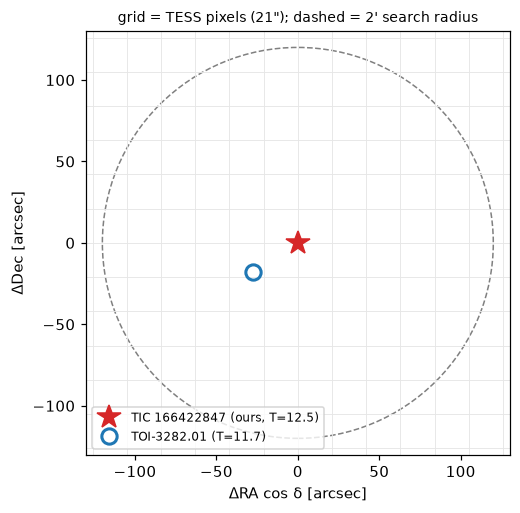

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
dra = lambda ra: (ra - s.ra) * np.cos(np.radians(s.dec)) * 3600  # arcsec east (flat-sky, fine at 2')
ddec = lambda dec: (dec - s.dec) * 3600
near_t = targets[(np.abs(targets.dec - s.dec) < 0.05)]
for x in np.arange(-126, 127, 21):
    ax.axvline(x, color="0.9", lw=0.6); ax.axhline(x, color="0.9", lw=0.6)
ax.plot(0, 0, "*", ms=16, color="C3", label=f"TIC {s.name} (ours, T={s.tmag:.1f})")
for k in nb.itertuples():
    ax.plot(dra(k.ra), ddec(k.dec), "o", ms=10, mfc="none", mew=2, color="C0", label=f"{k.obj_id} (T={k.tmag:.1f})")
ax.add_patch(plt.Circle((0, 0), NEIGHBOUR_RADIUS.to(u.arcsec).value, fill=False, ls="--", color="0.5"))
ax.set_xlim(-130, 130); ax.set_ylim(-130, 130); ax.set_aspect("equal")
ax.set_xlabel("ΔRA cos δ [arcsec]"); ax.set_ylabel("ΔDec [arcsec]")
ax.set_title("grid = TESS pixels (21\"); dashed = 2' search radius", fontsize=9); ax.legend(fontsize=8, loc="lower left")

## 7. Match 4: siblings inside our own sector

Our target list contains ~4,700 stars, some of them close to each other. If an EB sits
among them, its signal can appear in **several** of our light curves. Nobody has catalogued
it, so §6 cannot catch it. But we can match our own signals against each other with the same
machinery: pairs within 2′, period ratio, ephemeris.

Within a pair, the dilution argument tells which star is the source. The source has the
deeper *fractional* depth (its own light dominates its aperture), and the other star sees a
diluted copy. We only consider signals with SDE ≥ 9 and ≥ 2 transits as possible sources.
Below that, the "signal" is probably noise.

In [12]:
strong = sig[sig["pass_sde"] & sig["pass_n_transits"]]
sc = SkyCoord(strong["ra"].values, strong["dec"].values, unit="deg")
i, j, sep, _ = sc.search_around_sky(sc, NEIGHBOUR_RADIUS)
rows = []
for a, b, d in zip(i, j, sep):
    if a >= b:  # each pair once, no self-pairs
        continue
    sa, sb = strong.iloc[a], strong.iloc[b]
    pr = period_ratio(sa.period, sb.period)
    if pr is None:
        continue
    m = min(sa.period, sb.period)
    dt = (sa.T0 - sb.T0 + m / 2) % m - m / 2
    rows.append({"tic_a": sa.name, "tic_b": sb.name, "sep_arcsec": d.arcsec, "P_a": sa.period, "P_b": sb.period,
                 "dt_min": dt * 1440, "depth_a": sa.depth_ppm, "depth_b": sb.depth_ppm, "tmag_a": sa.tmag,
                 "tmag_b": sb.tmag, "pass_a": sa.passes_all, "pass_b": sb.passes_all})
siblings = pd.DataFrame(rows)
siblings.round(3)

,tic_a,tic_b,sep_arcsec,P_a,P_b,dt_min,depth_a,depth_b,tmag_a,tmag_b,pass_a,pass_b
0,257463348,257463349,4.147,2.066,2.067,2.334,7098.508,7675.367,13.389,13.329,False,False
1,58563278,58563279,4.247,0.733,0.733,-3.408,6576.130,9218.170,13.379,13.774,False,False
2,199738242,199738241,3.345,0.381,0.381,7.837,4677.453,8992.527,12.072,12.623,False,False
3,125115082,125115088,112.932,1.301,1.300,3.715,20652.760,7929.013,10.812,13.761,False,False


Four pairs. Three are separated by 3–4″, less than a pixel: these are **resolved double
stars** that the TIC lists separately and TESS cannot separate at all. Both light curves are
essentially the same pixels, so the same signal in both is expected, and the true host is
undetermined from TESS data alone.

The fourth pair is the interesting one: **TIC 125115082 and TIC 125115088, 113″ (5 pixels)
apart**, with the same period to 0.06 % and transits within a few minutes of each other. The
depths settle it. 082 is ~3 magnitudes (15×) brighter and has a 20,650 ppm dip. For 082
to cause 088's 7,930 ppm dip it needs only ≥ ~520 ppm (deblended formula), which it has. In the other direction,
faint 088 would need a ≥ 31 % eclipse of its own to cause 082's dip. That contradicts the
0.8 % dip we measure on 088 itself, in an aperture its own light dominates. So **125115082 is
the source, and 125115088 is a contaminated copy.** Neither passed vetting (082 has a
secondary eclipse, so it is an EB, and 088 failed `variability`), but in another sector
the copy could have slipped through, and this test would catch it.

In [13]:
r = siblings[siblings.sep_arcsec > 60].iloc[0]
for src, dst in [("a", "b"), ("b", "a")]:
    need = depth_needed_ppm(r[f"depth_{dst}"], r[f"tmag_{dst}"], r[f"tmag_{src}"])
    print(f"for TIC {int(r[f'tic_{src}'])} (T={r[f'tmag_{src}']:.2f}, depth {r[f'depth_{src}']:.0f} ppm) to cause "
          f"TIC {int(r[f'tic_{dst}'])}'s {r[f'depth_{dst}']:.0f} ppm dip it needs >= {need:.0f} ppm"
          f"  ->  {'possible' if need <= r[f'depth_{src}'] else 'impossible'}")

for TIC 125115082 (T=10.81, depth 20653 ppm) to cause TIC 125115088's 7929 ppm dip it needs >= 524 ppm  ->  possible
for TIC 125115088 (T=13.76, depth 7929 ppm) to cause TIC 125115082's 20653 ppm dip it needs >= 312218 ppm  ->  impossible


## 8. Gaia DR3 eclipsing binaries

The TESS EB catalog only covers sectors 1–26 and the brighter 2-minute targets, and the TOI
lists only contain what someone chose to submit. Gaia DR3 classified ~2.2 million eclipsing
binaries from its own photometry, all-sky and down to G ≈ 20. That makes it by far the most
complete list of *potential contaminating* EBs. It is far too big to download, so we query a
2′ cone around each candidate. VizieR accepts all positions in one request and labels each
returned row with the index `_q` of the position it belongs to.

Gaia gives each EB a frequency (`Freq`, cycles per day, so P = 1/Freq) and a position. Its
reference epoch convention is awkward to turn into a BTJD transit time, so for Gaia we match
**period only** (`ephemeris = unknown`). There is about one Gaia EB per 2′ cone on average,
and each has a ~0.5 % chance of matching by accident at tol = 0.2 % (§4). With 49 candidates
we expect ~0.25 false neighbour matches in total. That is acceptable for a flag a human will
look at.

**Self or neighbour?** The Gaia EB can be our *own* star: then it is a known EB, not a blend.
Gaia DR3 source IDs are (almost always) the same as DR2 IDs, and the TIC stores the DR2 ID, so
we compare IDs. As a fallback we use separation < 3″. Gaia positions are at epoch 2016 and the
TIC's at 2000, and nearby M dwarfs move up to ~1″/yr, so separation alone is not reliable.

In [14]:
def gaia_ebs_around(tics) -> pd.DataFrame:
    path = KNOWN_DIR / f"gaia_veb_sector_{SECTOR}_notebook.parquet"
    if path.exists():
        return pd.read_parquet(path)
    sub = sig.loc[list(tics)]
    res = Vizier(columns=["Source", "RA_ICRS", "DE_ICRS", "Freq"], row_limit=-1).query_region(
        SkyCoord(sub["ra"].values, sub["dec"].values, unit="deg"), radius=NEIGHBOUR_RADIUS, catalog="I/358/veb")
    g = res[0].to_pandas() if len(res) else pd.DataFrame(columns=["_q", "Source", "RA_ICRS", "DE_ICRS", "Freq"])
    g["tic_query"] = sub.index.values[g["_q"].astype(int) - 1]  # _q is 1-based
    g.to_parquet(path, index=False)
    return g


gaia = gaia_ebs_around(cand.index)
gaia["period"] = 1 / gaia["Freq"]
gaia["sep_arcsec"] = SkyCoord(gaia.RA_ICRS.values, gaia.DE_ICRS.values, unit="deg").separation(
    SkyCoord(sig.loc[gaia.tic_query, "ra"].values, sig.loc[gaia.tic_query, "dec"].values, unit="deg")).arcsec
gaia["self"] = (gaia["Source"].astype("int64").values == sig.loc[gaia.tic_query, "gaia_dr2_id"].astype("int64").values) | (gaia["sep_arcsec"] < 3)
gaia["match"] = [period_ratio(sig.loc[t, "period"], p) for t, p in zip(gaia.tic_query, gaia.period)]
print(f"{len(gaia)} Gaia EBs within 2' of the {len(cand)} candidates; {gaia['match'].notna().sum()} with a period match")
gaia[gaia["match"].notna()][["tic_query", "Source", "sep_arcsec", "self", "period", "match"]].round(4)

46 Gaia EBs within 2' of the 49 candidates; 9 with a period match


/home/jj/Desktop/science-projects/exoplanets-research/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2610: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)


,tic_query,Source,sep_arcsec,self,period,match
0,314196928,6723339954040854528,72.0976,False,0.5403,"(0.5, 0.0002708800109617268)"
3,341225835,6449704185988209664,51.7884,False,2.0188,"(1, 0.00021097089340212975)"
5,421229957,5922959054539461248,53.3210,False,0.5175,"(1, 1.8891196973372094e-05)"
9,73758713,5913137495127297408,57.8095,False,2.3876,"(1, 0.00041146485976761556)"
14,326123365,4035281964043767296,42.9381,False,1.6968,"(1, 0.00019287882394270313)"
15,88514687,6707873669423909888,31.8652,False,0.4581,"(1, 0.00033995257343830213)"
28,30450374,5955371729643296384,16.3718,False,0.6269,"(2, 0.0005689231531301994)"
31,149868302,5961086097758068992,50.3084,False,0.6174,"(1, 0.00045585201369692134)"
41,260817968,5925814554976194560,35.9954,False,2.5220,"(1, 0.0005909940139796763)"


Nine candidates have a Gaia EB with the same period (or an alias of it) within 2′. None of
them is the candidate itself (`self` would be True), so all nine are neighbours, 16″ to 72″
away, and our signal is very probably that EB's light. Against ~0.25 expected chance
matches, nine is far too many to be coincidence. Blended EBs are a large part of what
survives vetting.

## 9. Putting it together: `classify()`

For every signal we collect all matches (same-star rows, neighbour rows, siblings, Gaia EBs)
and assign **one class**, by priority. The first rule that applies wins:

| `known_class` | meaning |
|---|---|
| `known_planet` | same star, a confirmed planet with this ephemeris |
| `toi` / `ctoi` | same star, a TOI / CTOI with this ephemeris (its disposition says what TFOP thinks) |
| `known_eb` | same star is a catalogued EB (TESS-EB or Gaia) at this period or an alias |
| `neighbour` | a catalogued object (TOI, CTOI, planet, EB, Gaia EB) on a star within 2′ has this ephemeris: a blend, or a misattributed catalog entry (see `likely_source`) |
| `sibling` | another star in our own sector has the same signal and is the likelier source |
| `new_in_known_system` | the star has catalogued objects, but none at this period. **A possible additional planet!** |
| `new` | nothing matches |

The boolean columns from the plan (`known_toi`, `known_ctoi`, `known_planet`, `known_eb`,
`neighbour_match`) are kept as well. They are not exclusive: a confirmed planet is usually
also a TOI.

In [15]:
def classify(tic_id) -> dict:
    s = sig.loc[tic_id]
    out = {"known_planet": False, "known_toi": False, "known_ctoi": False, "known_eb": False,
           "neighbour_match": False, "sibling_match": False, "system_known": False, "known_ids": "",
           "nb_id": "", "nb_sep_arcsec": np.nan, "likely_source": ""}
    ids = []
    # --- same star ---
    for k in known[known["tic_id"] == tic_id].itertuples():
        out["system_known"] = True
        m = match_row(s, k)
        if m:
            out[{"planet": "known_planet", "toi": "known_toi", "ctoi": "known_ctoi", "tess_eb": "known_eb"}[k.catalog]] = True
            ids.append(f"{k.obj_id} [{k.disposition}]")
    for g in gaia[(gaia.tic_query == tic_id) & gaia.self & gaia.match.notna()].itertuples():
        out["known_eb"] = True; ids.append(f"Gaia DR3 {g.Source} [EB]")
    # --- neighbours: catalogs, Gaia, siblings; keep the closest match ---
    best = []
    for k in neighbours(tic_id).itertuples():
        m = match_row(s, k)
        if m:
            need, src = likely_source(s.depth_ppm, s.tmag, k.tmag, k.depth_ppm)
            best.append((k.sep_arcsec, f"{k.obj_id} on TIC {k.tic_id} [{k.disposition}]", src))
    for g in gaia[(gaia.tic_query == tic_id) & ~gaia.self & gaia.match.notna()].itertuples():
        best.append((g.sep_arcsec, f"Gaia DR3 {g.Source} [EB]", "unclear"))
    if best:
        out["neighbour_match"] = True
        out["nb_sep_arcsec"], out["nb_id"], out["likely_source"] = min(best)
    for r in siblings[(siblings.tic_a == tic_id) | (siblings.tic_b == tic_id)].itertuples():
        me, other = ("a", "b") if r.tic_a == tic_id else ("b", "a")
        need = depth_needed_ppm(getattr(r, f"depth_{me}"), getattr(r, f"tmag_{me}"), getattr(r, f"tmag_{other}"))
        if need <= getattr(r, f"depth_{other}"):  # the other star can explain our dip
            out["sibling_match"] = True
            if not best:
                out["nb_sep_arcsec"], out["nb_id"], out["likely_source"] = r.sep_arcsec, f"TIC {getattr(r, f'tic_{other}')} (sector {SECTOR})", "neighbour"
    out["known_ids"] = "; ".join(ids)
    out["known_class"] = (
        "known_planet" if out["known_planet"] else "toi" if out["known_toi"] else "ctoi" if out["known_ctoi"]
        else "known_eb" if out["known_eb"] else "neighbour" if out["neighbour_match"] else "sibling" if out["sibling_match"]
        else "new_in_known_system" if out["system_known"] else "new")
    return out


result = pd.DataFrame({t: classify(t) for t in cand.index}).T
result = cand[["period", "depth_ppm", "rp_earth", "snr", "flags"]].join(result)
print(result["known_class"].value_counts().to_string())

known_class
new             29
neighbour       11
known_planet     8
ctoi             1


In [16]:
cols = ["known_class", "period", "depth_ppm", "rp_earth", "snr", "flags", "known_ids", "nb_id", "nb_sep_arcsec", "likely_source"]
order = ["new", "new_in_known_system", "sibling", "neighbour", "known_eb", "ctoi", "toi", "known_planet"]
result.assign(o=result.known_class.map(order.index)).sort_values(["o", "snr"], ascending=[True, False])[cols].round(
    {"period": 4, "depth_ppm": 0, "rp_earth": 2, "snr": 1, "nb_sep_arcsec": 1})

,known_class,period,depth_ppm,rp_earth,snr,flags,known_ids,nb_id,nb_sep_arcsec,likely_source
tic_id,,,,,,,,,,
229804549,new,0.7321,2385.0,2.76,17.1,centroid,,,NaN,
160188205,new,0.7011,8511.0,4.19,14.0,centroid,,,NaN,
49143293,new,9.0489,42592.0,5.99,12.3,,,,NaN,
218663210,new,0.7885,7856.0,2.88,12.1,"v_shaped,centroid",,,NaN,
231888176,new,5.3141,2943.0,1.65,10.9,contamination,,,NaN,
217484923,new,9.0057,2789.0,1.54,10.5,"centroid,contamination",,,NaN,
61615837,new,1.1076,3558.0,2.36,10.4,centroid,,,NaN,
306101698,new,2.8790,4882.0,3.07,10.3,centroid,,,NaN,
214311908,new,5.6924,13793.0,4.39,10.3,"centroid,contamination",,,NaN,


How to read the final table, from the top:

- **`new`**: the signals nothing explains. These are what milestone 1 is after, the input
  to the report and to a human's eyes. Most still carry soft flags (centroid, contamination,
  V shape) from vetting, which the report must show next to them.
- **`neighbour`**: caught only by the neighbour search, either from the downloaded
  catalogs or from Gaia. Vetting could not reject these: each light curve, taken alone,
  looked fine. `likely_source` says whether the catalogued neighbour can actually explain the
  depth.
- **`known_planet`** and **`toi`**: recoveries. Every confirmed planet in our candidate list
  is recovered by TIC ID *and* ephemeris. That end-to-end check of steps 1–5 is the
  strongest evidence so far that the pipeline works.

## 10. Checklist for writing `src/known.py`

**Catalogs** (`fetch_catalogs(day, offline)`)

- TOI, CTOI (ExoFOP CSV), confirmed planets (`pscomppars` via TAP), TESS EBs (VizieR
  `J/ApJS/258/16`), stored raw in `data/known/YYYY-MM-DD/`. Download once per day.
  `--offline` uses the newest existing folder, `--refresh` forces a new download.
- Normalise to the one schema of §3 (`KNOWN_COLS`) with the epoch sanity cut.
- Gaia DR3 EBs (`I/358/veb`): one cone query for the candidate positions, cached per day and
  sector. By default only for `passes_all` rows (`--gaia-scope all` for every SDE ≥ 9 signal;
  the query is slower but still one request).

**Matching** for every row of the vetted table (TIC-ID and neighbour matching against local
catalogs is cheap, so do all 4,693; it also labels the *rejected* signals, which tells us
which known objects vetting threw out):

- same star → period ratio → ephemeris (§4–5),
- neighbours within `--radius` (default 2′) → same chain + dilution `likely_source` (§6),
- siblings in the sector (§7),
- Gaia EBs, self vs neighbour (§8),
- `classify()` priority of §9.

**Output** `data/search/sector_{N}_known.parquet`: all vetted columns + `known_class`,
the booleans, `known_ids`, `nb_id`, `nb_sep_arcsec`, `likely_source`. Sorted: `passes_all`
first, then `known_class` in the order *new, new_in_known_system, sibling, neighbour,
known_eb, ctoi, toi, known_planet*, then SNR. Plus a log summary: class counts among
`passes_all`, the list of `new` candidates, and **any confirmed planet or TOI in the sector
that vetting rejected** (a recall check on vetting: TOI-122 b should appear there, rejected by
`snr`).

**Not done here**

- Matching against the *TOI catalog's* own blend notes and comments (free text).
- Pixel-level confirmation of the source (difference imaging, TPF centroids): the only way to
  settle `likely_source = unclear` cases for good.